define the 4 control sets, the samples, the weights, the outcomes
all combinations = product of the lists
print how many

In [3]:
import sys
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../code")
import helpers

df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("specification_curve")

# The menu of reasonable choices (each one was used somewhere in notebook 04)
SIZE_AGE_JOBS = "log_population + log_density + share_under20 + share_65plus + jobs_per_capita"
CONTROL_SETS = {
    "M2: size, age, jobs":        SIZE_AGE_JOBS,
    "M3: + urban type, language": f"{SIZE_AGE_JOBS} + C(urban_rural) + C(language)",
    "M4: + canton fixed effects": f"{SIZE_AGE_JOBS} + C(urban_rural) + C(language) + C(canton)",
    "M4 + tax burden":            f"{SIZE_AGE_JOBS} + C(urban_rural) + C(language) + C(canton) + tax_burden_100k",
}
SAMPLES = {
    "All communes":                   lambda d: d,
    "Without intl-official communes": lambda d: d[d["share_intl"] <= 1],         # as in 04 §7
    "Without resort communes":        lambda d: d[d["filers_per_capita"] <= 1],  # as in 04 §7
}
WEIGHTS = {"Unweighted": False, "Population-weighted": True}
SA_OUTCOMES = {"SA rate (level)": "sa_rate", "SA rate (log)": "log_sa"}

sa_sample["log_sa"] = np.log(sa_sample["sa_rate"])
# For tax, one more sample: only the communes where SA is reported
TAX_SAMPLES = {**SAMPLES, "Same communes as SA": lambda d: d[d["code"].isin(sa_sample["code"])]}

# Every combination of the choices
sa_specs = list(product(CONTROL_SETS, SAMPLES, WEIGHTS, SA_OUTCOMES))
tax_specs = list(product(CONTROL_SETS, TAX_SAMPLES, WEIGHTS))
print(f"SA specifications: {len(sa_specs)} | urban tax slope specifications: {len(tax_specs)}")

SA specifications: 48 | urban tax slope specifications: 32


for each SA combination:
    filter the sample, fit, convert to %, store a row
for each tax combination:
    the same, with the urban slope
table of all rows → mark the baseline → save to CSV
summary: share positive / negative / significant, smallest / median / largest

In [4]:
import warnings
warnings.filterwarnings("ignore", message="covariance of constraints does not have full rank")


def run(formula, data, weighted, variable, outcome, scale_mean):
    """Fit one specification; return its coefficient as % change per point of foreign share."""
    m = helpers.fit_clustered(formula, data, weighted)
    low, high = m.conf_int().loc[variable]
    # Level outcome: divide by the mean SA rate; log outcome: already a share
    factor = 100 / scale_mean if outcome == "level" else 100
    return {"estimate": m.params[variable] * factor,
            "ci_low": low * factor, "ci_high": high * factor,
            "p_value": m.pvalues[variable], "n": int(m.nobs)}


rows = []
for controls, sample, weight, outcome in sa_specs:
    data = SAMPLES[sample](sa_sample)
    weights = data["population"] if WEIGHTS[weight] else None
    mean_sa = np.average(data["sa_rate"], weights=weights)
    kind = "level" if SA_OUTCOMES[outcome] == "sa_rate" else "log"
    result = run(f"{SA_OUTCOMES[outcome]} ~ foreign_share + {CONTROL_SETS[controls]}",
                 data, WEIGHTS[weight], "foreign_share", kind, mean_sa)
    rows.append({"result": "SA: foreign share", "controls": controls, "sample": sample,
                 "weights": weight, "outcome": outcome, **result})

# Tax: one foreign-share slope per commune type (as in 04 §5); we keep the urban one
urban = "C(urban_rural)[urban]:foreign_share"
for controls, sample, weight in tax_specs:
    data = TAX_SAMPLES[sample](tax_sample)
    result = run(f"log_tax ~ {CONTROL_SETS[controls]} + C(urban_rural) + C(urban_rural):foreign_share",
                 data, WEIGHTS[weight], urban, "log", None)
    rows.append({"result": "Tax: urban slope", "controls": controls, "sample": sample,
                 "weights": weight, "outcome": "Tax per resident (log)", **result})

specs = pd.DataFrame(rows)
# The specification of notebook 04 (M4, all communes, unweighted, SA in levels)
specs["baseline"] = ((specs["controls"] == "M4: + canton fixed effects")
                     & (specs["sample"] == "All communes")
                     & (specs["weights"] == "Unweighted")
                     & specs["outcome"].isin(["SA rate (level)", "Tax per resident (log)"]))
specs.to_csv(OUT / "table_all_specifications.csv", index=False)

summary = specs.groupby("result").agg(
    specifications=("estimate", "size"),
    share_positive=("estimate", lambda b: (b > 0).mean()),
    share_negative=("estimate", lambda b: (b < 0).mean()),
    share_significant_5pct=("p_value", lambda p: (p < 0.05).mean()),
    smallest=("estimate", "min"), median=("estimate", "median"), largest=("estimate", "max"))
summary.to_csv(OUT / "table_summary.csv")
summary.round(3)

,specifications,share_positive,share_negative,share_significant_5pct,smallest,median,largest
result,,,,,,,
SA: foreign share,48,1.0,0.0,0.917,0.960,1.948,3.025
Tax: urban slope,32,0.0,1.0,0.531,-1.964,-1.179,-0.243


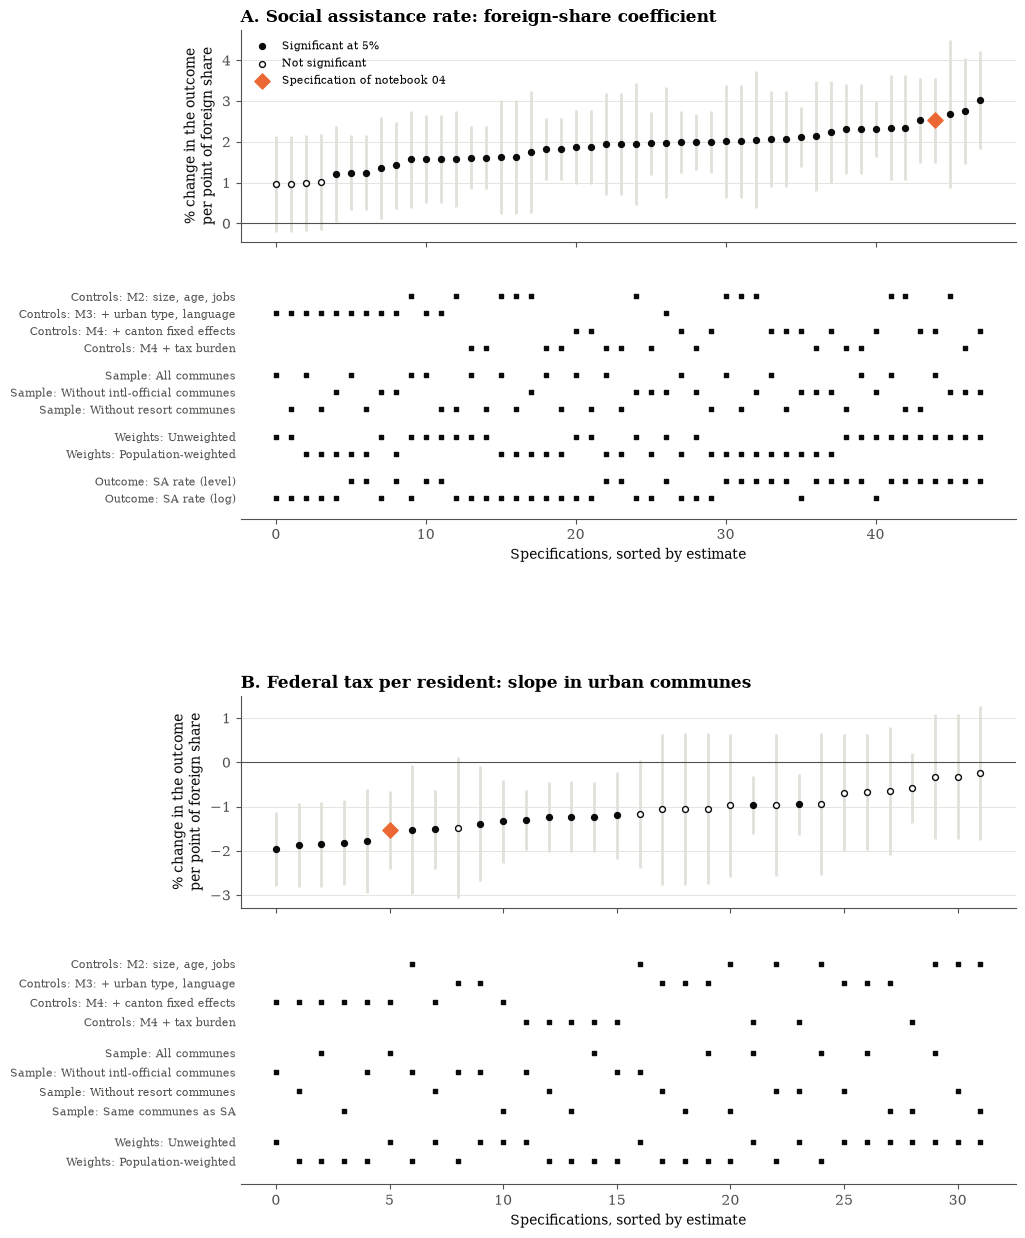

In [5]:
# The options of each choice, in a fixed order (same order in every panel)
DIMENSIONS = {
    "Controls": ("controls", list(CONTROL_SETS)),
    "Sample":   ("sample",   list(TAX_SAMPLES)),
    "Weights":  ("weights",  list(WEIGHTS)),
    "Outcome":  ("outcome",  list(SA_OUTCOMES)),
}
TITLES = {"SA: foreign share": "A. Social assistance rate: foreign-share coefficient",
          "Tax: urban slope": "B. Federal tax per resident: slope in urban communes"}


def plot_curve(s, ax_top, ax_bottom, title, legend=False):
    """Top: every estimate with its 95% interval, sorted. Bottom: the choices behind each one."""
    s = s.sort_values("estimate").reset_index(drop=True)
    x = np.arange(len(s))
    significant = (s["p_value"] < 0.05).to_numpy()

    ax_top.vlines(x, s["ci_low"], s["ci_high"], color=helpers.INK["grid"], linewidth=2)
    ax_top.scatter(x[significant], s["estimate"][significant], color=helpers.INK["primary"],
                   s=18, zorder=3, label="Significant at 5%")
    ax_top.scatter(x[~significant], s["estimate"][~significant], facecolor="white",
                   edgecolor=helpers.INK["primary"], s=18, zorder=3, label="Not significant")
    base = s.index[s["baseline"]]
    ax_top.scatter(base, s.loc[base, "estimate"], color=helpers.COLORS["urban_rural"]["intermediate"],
                   s=60, marker="D", zorder=4, label="Specification of notebook 04")
    ax_top.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax_top.set_title(title)
    ax_top.set_ylabel("% change in the outcome\nper point of foreign share")
    ax_top.grid(axis="y")
    if legend:
        ax_top.legend(loc="upper left", fontsize=8)

    labels, rows_y, y = [], [], 0
    for dimension, (column, options) in DIMENSIONS.items():
        options = [o for o in options if o in set(s[column])]
        if len(options) < 2:                           # tax has a single outcome: no row
            continue
        for option in options:
            used = (s[column] == option).to_numpy()
            ax_bottom.scatter(x[used], np.full(used.sum(), y), color=helpers.INK["primary"],
                              s=8, marker="s")
            labels.append(f"{dimension}: {option}")
            rows_y.append(y)
            y += 1
        y += 0.6                                       # gap between two kinds of choice
    ax_bottom.set_yticks(rows_y, labels, fontsize=8)
    ax_bottom.set_ylim(y - 0.4, -0.6)                  # first option on top
    ax_bottom.set_xlabel("Specifications, sorted by estimate")
    ax_bottom.spines["left"].set_visible(False)
    ax_bottom.tick_params(axis="y", length=0)


fig = plt.figure(figsize=(10, 13))
for i, (subfig, result) in enumerate(zip(fig.subfigures(2, 1, hspace=0.05), TITLES)):
    ax_top, ax_bottom = subfig.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
    plot_curve(specs[specs["result"] == result], ax_top, ax_bottom, TITLES[result], legend=(i == 0))
helpers.save_figure(fig, OUT / "fig_specification_curve.png")
plt.show()

In [6]:
# For each choice and option: the median estimate and the share of significant estimates
rows = []
for result in TITLES:
    s = specs[specs["result"] == result]
    for dimension, (column, options) in DIMENSIONS.items():
        for option in options:
            used = s[s[column] == option]
            if len(used) == 0 or s[column].nunique() < 2:
                continue
            rows.append({"result": result, "choice": dimension, "option": option,
                         "specifications": len(used),
                         "median estimate (%)": used["estimate"].median(),
                         "share significant at 5%": (used["p_value"] < 0.05).mean()})
table_choices = pd.DataFrame(rows).set_index(["result", "choice", "option"])
table_choices.to_csv(OUT / "table_by_choice.csv")
table_choices.round(2)

specifications  \
result            choice   option                                           
SA: foreign share Controls M2: size, age, jobs                         12   
                           M3: + urban type, language                  12   
                           M4: + canton fixed effects                  12   
                           M4 + tax burden                             12   
                  Sample   All communes                                16   
                           Without intl-official communes              16   
                           Without resort communes                     16   
                  Weights  Unweighted                                  24   
                           Population-weighted                         24   
                  Outcome  SA rate (level)                             24   
                           SA rate (log)                               24   
Tax: urban slope  Controls M2: size, age, jobs                          8   
                           M3: + urban type, language                   8   
                           M4: + canton fixed effects                   8   
                           M4 + tax burden                              8   
                  Sample   All communes                                 8   
                           Without intl-official communes               8   
                           Without resort communes                      8   
                           Same communes as SA                          8   
                  Weights  Unweighted                                  16   
                           Population-weighted                         16   

                                                           median estimate (%)  \
result            choice   option                                                
SA: foreign share Controls M2: size, age, jobs                            1.98   
                           M3: + urban type, language                     1.25   
                           M4: + canton fixed effects                     2.09   
                           M4 + tax burden                                1.95   
                  Sample   All communes                                   1.84   
                           Without intl-official communes                 2.02   
                           Without resort communes                        1.85   
                  Weights  Unweighted                                     1.96   
                           Population-weighted                            1.95   
                  Outcome  SA rate (level)                                2.07   
                           SA rate (log)                                  1.69   
Tax: urban slope  Controls M2: size, age, jobs                           -0.96   
                           M3: + urban type, language                    -1.06   
                           M4: + canton fixed effects                    -1.80   
                           M4 + tax burden                               -1.21   
                  Sample   All communes                                  -1.01   
                           Without intl-official communes                -1.43   
                           Without resort communes                       -1.02   
                           Same communes as SA                           -1.02   
                  Weights  Unweighted                                    -0.96   
                           Population-weighted                           -1.23   

                                                           share significant at 5%  
result            choice   option                                                   
SA: foreign share Controls M2: size, age, jobs                                1.00  
                           M3: + urban type, language                         0.67  
                           M4: + canton fixed effects       